# SHL Grammar Scoring Engine

## Objective

Build a machine learning model that predicts the grammar score
(1–5) of a 45–60 second spoken audio recording.

## Evaluation Metrics

- RMSE
- Pearson Correlation

## Approach

Audio → Speech Transcription → Linguistic & Audio Features → Regression Model → Grammar Score

In [ ]:
!pip install -q faster-whisper librosa soundfile nltk spacy lightgbm xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 84.3 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
import numpy as np
import librosa
import soundfile as sf

print("Environment ready!")

Environment ready!


In [16]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [17]:
!kaggle competitions download -c shl-hiring-assessment-2026 -p /content/shl_kaggle

100% 1.22G/1.22G [01:16<00:00, 17.2MB/s]



In [19]:
import os

download_dir = "/content/shl_kaggle"

for file in os.listdir(download_dir):
    path = os.path.join(download_dir, file)
    size_gb = os.path.getsize(path) / (1024**3)
    print(file, "→", round(size_gb, 2), "GB")

shl-hiring-assessment-2026.zip → 1.22 GB


In [ ]:
import os

path = "/content/shl-hiring-assessment-2026.zip"

print(round(os.path.getsize(path) / (1024**3), 2), "GB")

0.06 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'shl-hiring-assessment-2026.zip', 'sample_data']


In [20]:
import zipfile
import os

download_dir = "/content/shl_kaggle"

zip_file = [
    os.path.join(download_dir, f)
    for f in os.listdir(download_dir)
    if f.endswith(".zip")
][0]

extract_path = "/content/shl_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [21]:
import os

for root, dirs, files in os.walk("/content/shl_data"):
    level = root.replace("/content/shl_data", "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

shl_data/
  Dataset_Final/
    sample_submission.csv
    test.csv
    train.csv
    test/
      audio_154.wav
      audio_66.wav
      audio_11.wav
      audio_100.wav
      audio_201.wav
      audio_112.wav
      audio_153.wav
      audio_184.wav
      audio_76.wav
      audio_61.wav
    train/
      audio_301.wav
      audio_669.wav
      audio_513.wav
      audio_154.wav
      audio_66.wav
      audio_451.wav
      audio_351.wav
      audio_11.wav
      audio_587.wav
      audio_621.wav


In [22]:
import pandas as pd
import os

DATA_DIR = "/content/shl_data/Dataset_Final"

train_path = os.path.join(DATA_DIR, "train.csv")
test_path = os.path.join(DATA_DIR, "test.csv")
sample_path = os.path.join(DATA_DIR, "sample_submission.csv")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample = pd.read_csv(sample_path)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample.shape)

print("\nTrain columns:")
print(train.columns.tolist())

print("\nFirst 5 training rows:")
display(train.head())

Train shape: (769, 2)
Test shape: (216, 2)
Sample submission shape: (204, 2)

Train columns:
['filename', 'label']

First 5 training rows:


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


In [24]:
print("Label statistics:")
print(train["label"].describe())

print("\nUnique labels:")
print(sorted(train["label"].unique()))

print("\nLabel counts:")
print(train["label"].value_counts().sort_index())

Label statistics:
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

Unique labels:
[np.float64(0.0), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]

Label counts:
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


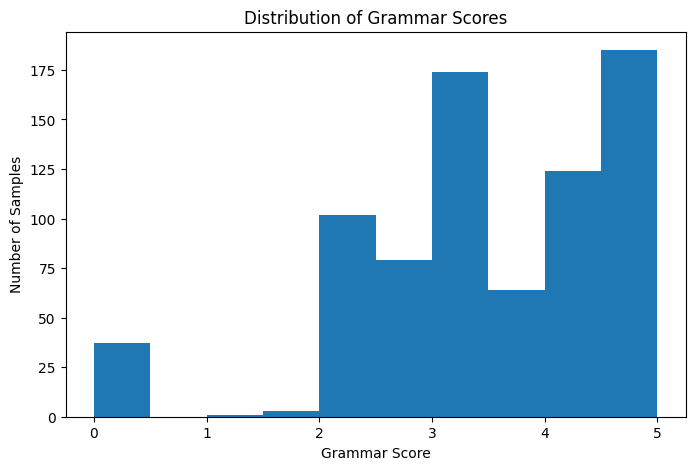

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(train["label"], bins=10)
plt.xlabel("Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Distribution of Grammar Scores")
plt.show()

In [26]:
import os

TRAIN_AUDIO_DIR = os.path.join(DATA_DIR, "train")
TEST_AUDIO_DIR = os.path.join(DATA_DIR, "test")

train_files = set(os.listdir(TRAIN_AUDIO_DIR))
test_files = set(os.listdir(TEST_AUDIO_DIR))

print("Training CSV files:", len(train))
print("Training audio files:", len(train_files))

print("Test CSV files:", len(test))
print("Test audio files:", len(test_files))

missing_train = set(train["filename"]) - train_files
missing_test = set(test["filename"]) - test_files

print("\nMissing training audio:", len(missing_train))
print("Missing test audio:", len(missing_test))

if missing_train:
    print("Missing train files:", list(missing_train)[:10])

if missing_test:
    print("Missing test files:", list(missing_test)[:10])

Training CSV files: 769
Training audio files: 769
Test CSV files: 216
Test audio files: 216

Missing training audio: 0
Missing test audio: 0


In [27]:
import librosa
import os
import numpy as np

sample_files = train["filename"].head(10)

for filename in sample_files:
    path = os.path.join(TRAIN_AUDIO_DIR, filename)

    audio, sr = librosa.load(path, sr=None, mono=True)

    duration = len(audio) / sr

    print(
        f"{filename:20s} | "
        f"Duration: {duration:.2f}s | "
        f"Sample rate: {sr} Hz | "
        f"Samples: {len(audio)}"
    )

audio_192.wav        | Duration: 60.51s | Sample rate: 16000 Hz | Samples: 968134
audio_436.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195
audio_447.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195
audio_126.wav        | Duration: 45.06s | Sample rate: 16000 Hz | Samples: 720960
audio_61.wav         | Duration: 45.30s | Sample rate: 16000 Hz | Samples: 724800
audio_639.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195
audio_703.wav        | Duration: 52.16s | Sample rate: 16000 Hz | Samples: 834560
audio_509.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195
audio_672.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195
audio_344.wav        | Duration: 60.07s | Sample rate: 16000 Hz | Samples: 961195


In [28]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

CUDA available: True
GPU: Tesla T4


In [29]:
from faster_whisper import WhisperModel

MODEL_SIZE = "small.en"

whisper_model = WhisperModel(
    MODEL_SIZE,
    device="cuda",
    compute_type="float16"
)

print("Whisper model loaded successfully!")

Whisper model loaded successfully!


In [31]:
!pip install -q --upgrade av

In [33]:
!pip uninstall -y av faster-whisper
!pip install -q av==14.4.0 faster-whisper

Found existing installation: av 19.0.1
Uninstalling av-19.0.1:
  Successfully uninstalled av-19.0.1
Found existing installation: faster-whisper 1.2.1
Uninstalling faster-whisper-1.2.1:
  Successfully uninstalled faster-whisper-1.2.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 103.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [2]:
!pip install -q faster-whisper av==14.4.0

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [4]:
import sys

!{sys.executable} -m pip install -q faster-whisper av==14.4.0

print("Installation finished.")

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
Installation finished.


In [5]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "faster-whisper"],
    capture_output=True,
    text=True
)

print(result.stdout)

In [6]:
!pip install -q openai-whisper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 42.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
import whisper

print("Whisper version:", whisper.__version__)

Whisper version: 20250625


In [8]:
import whisper
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

whisper_model = whisper.load_model("small", device=device)

print("Device:", device)
print("Whisper model loaded successfully!")

100%|████████████████████████████████████████| 461M/461M [00:01<00:00, 282MiB/s]


Device: cuda
Whisper model loaded successfully!


In [10]:
import os

DATA_DIR = "/content/shl_data/Dataset_Final"
TRAIN_AUDIO_DIR = os.path.join(DATA_DIR, "train")

filename = "audio_192.wav"
audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

result = whisper_model.transcribe(
    audio_path,
    language="en",
    fp16=True
)

transcript = result["text"].strip()

print("File:", filename)
print("\nTranscript:\n")
print(transcript)

File: audio_192.wav

Transcript:

The plate round is very, very beautiful and fun. There are, there are plates like the marigold round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of pair. One sits in it and the other sits in it. We'll have to push and the marigold round, which was kind of nice. And most of them play football. On some parks, why others? So, the swing, some of the kids like to build sand castles. And most times, the addition of instrument children, laughing kids.


In [11]:
import os
import pandas as pd
import whisper
from tqdm.auto import tqdm

# Paths
DATA_DIR = "/content/shl_data/Dataset_Final"
TRAIN_AUDIO_DIR = os.path.join(DATA_DIR, "train")

# Make sure training data is loaded
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# Output file
TRANSCRIPT_PATH = "/content/train_transcripts.csv"

# Load existing transcripts if we already have some
if os.path.exists(TRANSCRIPT_PATH):
    transcripts_df = pd.read_csv(TRANSCRIPT_PATH)
    completed = set(transcripts_df["filename"])
    print(f"Found {len(completed)} existing transcripts. Resuming...")
else:
    transcripts_df = pd.DataFrame(columns=["filename", "transcript"])
    completed = set()

# Transcribe remaining files
new_rows = []

for filename in tqdm(train["filename"], desc="Transcribing training audio"):
    if filename in completed:
        continue

    audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

    try:
        result = whisper_model.transcribe(
            audio_path,
            language="en",
            fp16=True
        )

        transcript = result["text"].strip()

        new_rows.append({
            "filename": filename,
            "transcript": transcript
        })

    except Exception as e:
        print(f"\nError processing {filename}: {e}")

    # Save every 25 files so progress isn't lost
    if len(new_rows) >= 25:
        transcripts_df = pd.concat(
            [transcripts_df, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        transcripts_df.to_csv(TRANSCRIPT_PATH, index=False)
        new_rows = []

# Save remaining transcripts
if new_rows:
    transcripts_df = pd.concat(
        [transcripts_df, pd.DataFrame(new_rows)],
        ignore_index=True
    )

transcripts_df.to_csv(TRANSCRIPT_PATH, index=False)

print("\nDone!")
print("Total transcripts:", len(transcripts_df))
print("Saved to:", TRANSCRIPT_PATH)

Transcribing training audio:   0%|          | 0/769 [00:00<?, ?it/s]


Done!
Total transcripts: 769
Saved to: /content/train_transcripts.csv


In [12]:
import pandas as pd

# Load training labels
train = pd.read_csv("/content/shl_data/Dataset_Final/train.csv")

# Load Whisper transcripts
transcripts = pd.read_csv("/content/train_transcripts.csv")

# Merge using filename
train_data = train.merge(
    transcripts,
    on="filename",
    how="left"
)

print("Shape:", train_data.shape)
print("\nColumns:")
print(train_data.columns.tolist())

print("\nMissing transcripts:", train_data["transcript"].isna().sum())

print("\nSample:")
display(train_data.head(10))

Shape: (769, 3)

Columns:
['filename', 'label', 'transcript']

Missing transcripts: 6

Sample:


,filename,label,transcript
0,audio_192.wav,3.0,"The plate round is very, very beautiful and fu..."
1,audio_436.wav,3.0,"The scene of a school playground, our playgrou..."
2,audio_447.wav,3.5,My favorite place to visit is the beach. I lov...
3,audio_126.wav,2.0,Once upon a time we with five friends went on ...
4,audio_61.wav,2.0,"Well, when I was a child I remember I went to ..."
5,audio_639.wav,2.5,The best thing of my life was probably when I ...
6,audio_703.wav,2.0,I don't know if there are many. I don't know i...
7,audio_509.wav,3.0,"a smoothing effect. Besides this, I also have ..."
8,audio_672.wav,4.0,The school playground is very big and is very ...
9,audio_344.wav,4.0,My number one goal in life is to become the be...


In [14]:
missing_files = train_data.loc[
    train_data["transcript"].isna(),
    "filename"
].tolist()

print("Missing transcript files:")
for f in missing_files:
    print(f)

Missing transcript files:
audio_5069.wav
audio_5056.wav
audio_5058.wav
audio_5049.wav
audio_5042.wav
audio_5060.wav


In [18]:
import soundfile as sf
import os

for filename in missing_files:
    path = os.path.join(TRAIN_AUDIO_DIR, filename)

    info = sf.info(path)

    print(f"\n{filename}")
    print("Format:", info.format)
    print("Subtype:", info.subtype)
    print("Channels:", info.channels)
    print("Sample rate:", info.samplerate)
    print("Frames:", info.frames)


audio_5069.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961195

audio_5056.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961280

audio_5058.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961195

audio_5049.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961195

audio_5042.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961195

audio_5060.wav
Format: WAV
Subtype: PCM_16
Channels: 1
Sample rate: 16000
Frames: 961195


In [19]:
import re
import numpy as np
import pandas as pd

def extract_text_features(text):
    if not isinstance(text, str) or not text.strip():
        return {
            "word_count": 0,
            "sentence_count": 0,
            "avg_sentence_length": 0,
            "unique_word_ratio": 0,
            "repetition_ratio": 0,
            "filler_count": 0,
            "filler_ratio": 0,
        }

    text = text.lower().strip()

    # Words
    words = re.findall(r"\b[a-zA-Z']+\b", text)

    # Sentences
    sentences = re.split(r"[.!?]+", text)
    sentences = [s.strip() for s in sentences if s.strip()]

    word_count = len(words)
    sentence_count = len(sentences)

    unique_words = len(set(words))

    # Repeated words
    repetition_count = word_count - unique_words

    # Common spoken fillers
    fillers = {
        "um", "uh", "erm", "hmm",
        "like", "actually", "basically",
        "you", "know"
    }

    filler_count = sum(1 for word in words if word in fillers)

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "avg_sentence_length": (
            word_count / sentence_count if sentence_count > 0 else 0
        ),
        "unique_word_ratio": (
            unique_words / word_count if word_count > 0 else 0
        ),
        "repetition_ratio": (
            repetition_count / word_count if word_count > 0 else 0
        ),
        "filler_count": filler_count,
        "filler_ratio": (
            filler_count / word_count if word_count > 0 else 0
        ),
    }


# Extract features
text_features = train_data["transcript"].apply(extract_text_features)

text_features_df = pd.DataFrame(text_features.tolist())

# Combine with original data
train_features = pd.concat(
    [
        train_data[["filename", "label"]],
        text_features_df
    ],
    axis=1
)

print("Feature shape:", train_features.shape)

display(train_features.head(10))

Feature shape: (769, 9)


,filename,label,word_count,sentence_count,avg_sentence_length,unique_word_ratio,repetition_ratio,filler_count,filler_ratio
0,audio_192.wav,3.0,94,10,9.400000,0.606383,0.393617,4,0.042553
1,audio_436.wav,3.0,109,5,21.800000,0.477064,0.522936,6,0.055046
2,audio_447.wav,3.5,147,12,12.250000,0.517007,0.482993,1,0.006803
3,audio_126.wav,2.0,86,2,43.000000,0.488372,0.511628,3,0.034884
4,audio_61.wav,2.0,78,5,15.600000,0.576923,0.423077,2,0.025641
5,audio_639.wav,2.5,100,5,20.000000,0.630000,0.370000,0,0.000000
6,audio_703.wav,2.0,98,12,8.166667,0.551020,0.448980,4,0.040816
7,audio_509.wav,3.0,126,10,12.600000,0.650794,0.349206,2,0.015873
8,audio_672.wav,4.0,115,10,11.500000,0.626087,0.373913,1,0.008696
9,audio_344.wav,4.0,111,6,18.500000,0.594595,0.405405,0,0.000000


Correlation with grammar score:


,correlation
filler_ratio,-0.051012
repetition_ratio,-0.041870
avg_sentence_length,-0.014878
filler_count,0.062531
sentence_count,0.187001
unique_word_ratio,0.230858
word_count,0.387767


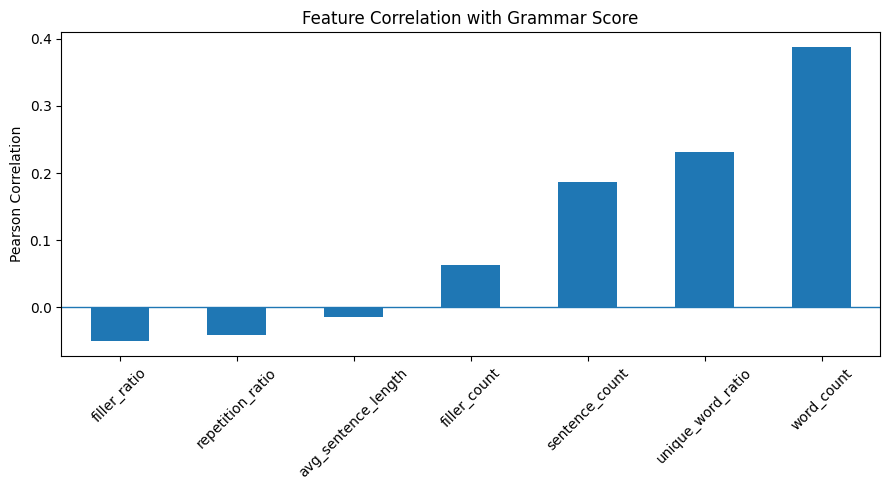

In [20]:
import matplotlib.pyplot as plt

correlations = (
    train_features
    .drop(columns=["filename"])
    .corr()["label"]
    .drop("label")
    .sort_values()
)

print("Correlation with grammar score:")
display(correlations.to_frame("correlation"))

# Visualize
plt.figure(figsize=(9, 5))
correlations.plot(kind="bar")
plt.axhline(0, linewidth=1)
plt.title("Feature Correlation with Grammar Score")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

# Features
feature_cols = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "unique_word_ratio",
    "repetition_ratio",
    "filler_count",
    "filler_ratio"
]

X = train_features[feature_cols]
y = train_features["label"]

# Model
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

# Metrics
rmse = np.sqrt(mean_squared_error(y, predictions))
pearson = pearsonr(y, predictions)[0]

print("Baseline Results")
print("----------------")
print(f"RMSE:    {rmse:.4f}")
print(f"Pearson: {pearson:.4f}")

Baseline Results
----------------
RMSE:    1.0927
Pearson: 0.4808


In [22]:
import librosa
import numpy as np
import pandas as pd
import os
from tqdm.auto import tqdm

def extract_audio_features(audio_path):
    audio, sr = librosa.load(
        audio_path,
        sr=16000,
        mono=True
    )

    duration = len(audio) / sr

    # Energy
    rms = librosa.feature.rms(y=audio)[0]

    # Zero crossing rate
    zcr = librosa.feature.zero_crossing_rate(audio)[0]

    # MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    features = {
        "duration": duration,

        "rms_mean": np.mean(rms),
        "rms_std": np.std(rms),

        "zcr_mean": np.mean(zcr),
        "zcr_std": np.std(zcr),
    }

    # MFCC mean + standard deviation
    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    return features


audio_features = []

for filename in tqdm(
    train["filename"],
    desc="Extracting audio features"
):
    path = os.path.join(TRAIN_AUDIO_DIR, filename)

    features = extract_audio_features(path)
    features["filename"] = filename

    audio_features.append(features)

audio_features_df = pd.DataFrame(audio_features)

print("Audio feature shape:", audio_features_df.shape)

display(audio_features_df.head())

Extracting audio features:   0%|          | 0/769 [00:00<?, ?it/s]

Audio feature shape: (769, 32)


,duration,rms_mean,rms_std,zcr_mean,zcr_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,...,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,filename
0,60.508375,0.031786,0.038404,0.084768,0.053518,-403.835876,121.629181,103.576317,68.035660,-14.213526,...,9.175093,-6.111349,7.005802,-11.947042,8.755231,-8.226156,6.883492,-6.238203,5.747041,audio_192.wav
1,60.074688,0.068651,0.055423,0.142977,0.127519,-287.111023,81.686005,72.087601,56.021065,5.334724,...,16.002327,-8.470199,13.448155,-9.261224,11.554407,-9.040758,13.295260,4.751498,13.532232,audio_436.wav
2,60.074688,0.054421,0.051533,0.146870,0.129777,-324.808228,86.514740,97.828194,59.010967,18.635796,...,16.530882,-8.570185,16.668097,3.306297,13.158398,-3.113312,11.855078,-0.866495,11.763124,audio_447.wav
3,45.060000,0.013778,0.012183,0.059477,0.036870,-489.320648,124.842300,111.792908,53.296017,0.751581,...,15.149113,-21.515909,15.097207,-12.347360,11.821060,-9.993058,10.599061,-17.710951,11.394984,audio_126.wav
4,45.300000,0.009330,0.008970,0.169988,0.128430,-483.866028,159.520401,51.975899,58.754555,-21.642136,...,16.179859,-18.795963,16.087770,-8.590364,13.599858,3.873606,10.692766,-17.764481,15.302751,audio_61.wav


In [23]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

# Merge linguistic + audio features
combined = train_features.merge(
    audio_features_df,
    on="filename",
    how="inner"
)

# Remove filename and target
feature_cols = [
    c for c in combined.columns
    if c not in ["filename", "label"]
]

X = combined[feature_cols]
y = combined["label"]

print("Total features:", len(feature_cols))
print("Dataset shape:", X.shape)

# Model
model = RandomForestRegressor(
    n_estimators=400,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Same CV setup as baseline
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

# Metrics
rmse = np.sqrt(mean_squared_error(y, predictions))
pearson = pearsonr(y, predictions)[0]

print("\nCombined Model Results")
print("----------------------")
print(f"RMSE:    {rmse:.4f}")
print(f"Pearson: {pearson:.4f}")

Total features: 38
Dataset shape: (769, 38)

Combined Model Results
----------------------
RMSE:    0.7605
Pearson: 0.7902


In [24]:
filename = "audio_192.wav"
audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

result = whisper_model.transcribe(
    audio_path,
    language="en",
    fp16=True
)

print("Number of segments:", len(result["segments"]))

for segment in result["segments"][:10]:
    print(
        f"{segment['start']:.2f}s - "
        f"{segment['end']:.2f}s | "
        f"{segment['text'].strip()}"
    )

Number of segments: 10
0.00s - 14.64s | The plate round is very, very beautiful and fun.
14.64s - 21.56s | There are, there are plates like the marigold round, the swing.
21.56s - 24.56s | The students usually enjoy the swing.
24.56s - 29.08s | It has to be like, it's more like a game of pair.
29.08s - 31.64s | One sits in it and the other sits in it.
31.64s - 37.72s | We'll have to push and the marigold round, which was kind of nice.
37.72s - 45.72s | And most of them play football.
45.72s - 47.92s | On some parks, why others?
47.92s - 54.04s | So, the swing, some of the kids like to build sand castles.
54.04s - 60.36s | And most times, the addition of instrument children, laughing kids.


In [25]:
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

SPEECH_FEATURES_PATH = "/content/speech_features.csv"

# Resume support
if os.path.exists(SPEECH_FEATURES_PATH):
    speech_features_df = pd.read_csv(SPEECH_FEATURES_PATH)
    completed = set(speech_features_df["filename"])
    print(f"Found {len(completed)} existing files. Resuming...")
else:
    speech_features_df = pd.DataFrame()
    completed = set()

new_rows = []

for filename in tqdm(
    train["filename"],
    desc="Extracting speech features"
):
    if filename in completed:
        continue

    audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

    try:
        result = whisper_model.transcribe(
            audio_path,
            language="en",
            fp16=True
        )

        segments = result["segments"]

        # Segment timestamps
        starts = [s["start"] for s in segments]
        ends = [s["end"] for s in segments]

        # Audio duration
        duration = librosa.get_duration(path=audio_path)

        # Pauses between consecutive Whisper segments
        pauses = []

        for i in range(1, len(segments)):
            gap = starts[i] - ends[i - 1]

            if gap > 0.1:
                pauses.append(gap)

        # Total speech time
        speech_time = sum(
            max(0, end - start)
            for start, end in zip(starts, ends)
        )

        pause_time = max(0, duration - speech_time)

        # Transcript word count
        word_count = len(
            result["text"].strip().split()
        )

        # Speech rate
        speech_rate = (
            word_count / speech_time
            if speech_time > 0 else 0
        )

        new_rows.append({
            "filename": filename,
            "speech_time": speech_time,
            "pause_time": pause_time,
            "pause_count": len(pauses),
            "avg_pause": np.mean(pauses) if pauses else 0,
            "max_pause": np.max(pauses) if pauses else 0,
            "speech_ratio": speech_time / duration if duration > 0 else 0,
            "words_per_second": speech_rate,
            "whisper_segments": len(segments)
        })

    except Exception as e:
        print(f"\nError: {filename} -> {e}")

    # Save every 25 files
    if len(new_rows) >= 25:
        batch_df = pd.DataFrame(new_rows)

        speech_features_df = pd.concat(
            [speech_features_df, batch_df],
            ignore_index=True
        )

        speech_features_df.to_csv(
            SPEECH_FEATURES_PATH,
            index=False
        )

        completed.update(batch_df["filename"])
        new_rows = []

# Save remaining
if new_rows:
    speech_features_df = pd.concat(
        [speech_features_df, pd.DataFrame(new_rows)],
        ignore_index=True
    )

speech_features_df.to_csv(
    SPEECH_FEATURES_PATH,
    index=False
)

print("\nDone!")
print("Speech feature rows:", len(speech_features_df))
display(speech_features_df.head())

Extracting speech features:   0%|          | 0/769 [00:00<?, ?it/s]


Done!
Speech feature rows: 769


,filename,speech_time,pause_time,pause_count,avg_pause,max_pause,speech_ratio,words_per_second,whisper_segments
0,audio_192.wav,60.36,0.148375,0,0.0,0.0,0.997548,1.557323,10
1,audio_436.wav,60.04,0.034687,0,0.0,0.0,0.999423,1.815456,10
2,audio_447.wav,56.04,4.034687,0,0.0,0.0,0.932839,2.623126,12
3,audio_126.wav,46.96,0.000000,0,0.0,0.0,1.042166,1.831346,5
4,audio_61.wav,45.20,0.100000,0,0.0,0.0,0.997792,1.725664,5


In [26]:
def calculate_speech_features(segments, duration, word_count):
    if not segments:
        return {
            "speech_time": 0,
            "pause_time": duration,
            "pause_count": 0,
            "avg_pause": 0,
            "max_pause": 0,
            "speech_ratio": 0,
            "words_per_second": 0,
            "whisper_segments": 0
        }

    intervals = sorted(
        [(s["start"], s["end"]) for s in segments]
    )

    # Merge overlapping intervals
    merged = []

    for start, end in intervals:
        if not merged or start > merged[-1][1]:
            merged.append([start, end])
        else:
            merged[-1][1] = max(merged[-1][1], end)

    speech_time = sum(
        end - start
        for start, end in merged
    )

    # Actual gaps between merged speech regions
    pauses = []

    for i in range(1, len(merged)):
        gap = merged[i][0] - merged[i - 1][1]

        if gap > 0.1:
            pauses.append(gap)

    pause_time = sum(pauses)

    return {
        "speech_time": speech_time,
        "pause_time": pause_time,
        "pause_count": len(pauses),
        "avg_pause": np.mean(pauses) if pauses else 0,
        "max_pause": np.max(pauses) if pauses else 0,
        "speech_ratio": min(speech_time / duration, 1.0),
        "words_per_second": (
            word_count / speech_time
            if speech_time > 0 else 0
        ),
        "whisper_segments": len(segments)
    }

In [27]:
for filename in ["audio_192.wav", "audio_126.wav"]:

    audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

    result = whisper_model.transcribe(
        audio_path,
        language="en",
        fp16=True
    )

    duration = librosa.get_duration(path=audio_path)
    word_count = len(result["text"].strip().split())

    features = calculate_speech_features(
        result["segments"],
        duration,
        word_count
    )

    print(f"\n{filename}")
    for key, value in features.items():
        print(f"{key}: {value}")


audio_192.wav
speech_time: 60.36
pause_time: 0
pause_count: 0
avg_pause: 0
max_pause: 0
speech_ratio: 0.997547860110274
words_per_second: 1.557322730284957
whisper_segments: 10

audio_126.wav
speech_time: 46.959999999999994
pause_time: 0
pause_count: 0
avg_pause: 0
max_pause: 0
speech_ratio: 1.0
words_per_second: 1.831345826235094
whisper_segments: 5


In [28]:
SPEECH_FEATURES_PATH = "/content/speech_features_corrected.csv"

speech_rows = []

for filename in tqdm(
    train["filename"],
    desc="Rebuilding speech features"
):
    audio_path = os.path.join(TRAIN_AUDIO_DIR, filename)

    try:
        result = whisper_model.transcribe(
            audio_path,
            language="en",
            fp16=True
        )

        duration = librosa.get_duration(path=audio_path)
        word_count = len(result["text"].strip().split())

        features = calculate_speech_features(
            result["segments"],
            duration,
            word_count
        )

        features["filename"] = filename
        speech_rows.append(features)

        # Save progress every 25 files
        if len(speech_rows) % 25 == 0:
            pd.DataFrame(speech_rows).to_csv(
                SPEECH_FEATURES_PATH,
                index=False
            )

    except Exception as e:
        print(f"\nError processing {filename}: {e}")

speech_features_df = pd.DataFrame(speech_rows)

speech_features_df.to_csv(
    SPEECH_FEATURES_PATH,
    index=False
)

print("\nDone!")
print("Rows:", len(speech_features_df))
print("Max speech ratio:", speech_features_df["speech_ratio"].max())
print("Min speech ratio:", speech_features_df["speech_ratio"].min())

display(speech_features_df.head())


Rebuilding speech features:   0%|          | 0/769 [00:00<?, ?it/s]


Done!
Rows: 769
Max speech ratio: 1.0
Min speech ratio: 0.0


,speech_time,pause_time,pause_count,avg_pause,max_pause,speech_ratio,words_per_second,whisper_segments,filename
0,60.36,0.0,0,0.0,0.0,0.997548,1.557323,10,audio_192.wav
1,60.04,0.0,0,0.0,0.0,0.999423,1.815456,10,audio_436.wav
2,56.04,0.0,0,0.0,0.0,0.932839,2.623126,12,audio_447.wav
3,46.96,0.0,0,0.0,0.0,1.000000,1.831346,5,audio_126.wav
4,45.20,0.0,0,0.0,0.0,0.997792,1.725664,5,audio_61.wav


In [29]:
# Merge all feature sets
final_features = (
    train_features
    .merge(audio_features_df, on="filename", how="inner")
    .merge(speech_features_df, on="filename", how="inner")
)

# All model features
feature_cols = [
    c for c in final_features.columns
    if c not in ["filename", "label"]
]

X = final_features[feature_cols]
y = final_features["label"]

print("Total features:", len(feature_cols))
print("Dataset shape:", X.shape)

# Random Forest
model = RandomForestRegressor(
    n_estimators=400,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

rmse = np.sqrt(mean_squared_error(y, predictions))
pearson = pearsonr(y, predictions)[0]

print("\nFinal Feature Model")
print("-------------------")
print(f"RMSE:    {rmse:.4f}")
print(f"Pearson: {pearson:.4f}")

Total features: 46
Dataset shape: (769, 46)

Final Feature Model
-------------------
RMSE:    0.7596
Pearson: 0.7909


In [30]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=20,
    min_child_samples=15,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

predictions_lgbm = cross_val_predict(
    lgbm_model,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

rmse_lgbm = np.sqrt(mean_squared_error(y, predictions_lgbm))
pearson_lgbm = pearsonr(y, predictions_lgbm)[0]

print("LightGBM")
print("--------")
print(f"RMSE:    {rmse_lgbm:.4f}")
print(f"Pearson: {pearson_lgbm:.4f}")

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


LightGBM
--------
RMSE:    0.7517
Pearson: 0.7947


In [31]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

predictions_xgb = cross_val_predict(
    xgb_model,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

rmse_xgb = np.sqrt(mean_squared_error(y, predictions_xgb))
pearson_xgb = pearsonr(y, predictions_xgb)[0]

print("XGBoost")
print("-------")
print(f"RMSE:    {rmse_xgb:.4f}")
print(f"Pearson: {pearson_xgb:.4f}")

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


XGBoost
-------
RMSE:    0.7431
Pearson: 0.8000


In [32]:
# Train XGBoost on the full training dataset
xgb_model.fit(X, y)

# Feature importance
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 20 Features")
print("----------------")
display(importance_df.head(20))

Top 20 Features
----------------


,feature,importance
10,zcr_mean,0.155769
12,mfcc_1_mean,0.089645
15,mfcc_2_std,0.072295
0,word_count,0.052480
14,mfcc_2_mean,0.039629
17,mfcc_3_std,0.039274
3,unique_word_ratio,0.035198
27,mfcc_8_std,0.033297
23,mfcc_6_std,0.030835
4,repetition_ratio,0.030194


In [33]:
xgb_tuned = XGBRegressor(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=3,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

predictions_tuned = cross_val_predict(
    xgb_tuned,
    X,
    y,
    cv=kf,
    n_jobs=-1
)

rmse_tuned = np.sqrt(mean_squared_error(y, predictions_tuned))
pearson_tuned = pearsonr(y, predictions_tuned)[0]

print("Tuned XGBoost")
print("-------------")
print(f"RMSE:    {rmse_tuned:.4f}")
print(f"Pearson: {pearson_tuned:.4f}")

Tuned XGBoost
-------------
RMSE:    0.7424
Pearson: 0.8005


In [34]:
import whisper
import pandas as pd
from tqdm.auto import tqdm

# Load test data
test_df = pd.read_csv("/content/shl_data/Dataset_Final/test.csv")

# Load Whisper model
whisper_model = whisper.load_model("small", device="cuda")

test_transcripts = []

for filename in tqdm(test_df["filename"], desc="Transcribing test audio"):
    audio_path = f"/content/shl_data/Dataset_Final/test/{filename}"

    result = whisper_model.transcribe(
        audio_path,
        fp16=True,
        verbose=False
    )

    test_transcripts.append({
        "filename": filename,
        "transcript": result["text"].strip()
    })

test_transcripts_df = pd.DataFrame(test_transcripts)

# Save so we don't have to transcribe again
test_transcripts_df.to_csv(
    "/content/test_transcripts.csv",
    index=False
)

print("Test transcripts:", len(test_transcripts_df))
print("Empty transcripts:",
      (test_transcripts_df["transcript"].str.len() == 0).sum())

display(test_transcripts_df.head())

Transcribing test audio:   0%|          | 0/216 [00:00<?, ?it/s]

Detected language: Tagalog



100%|██████████| 4506/4506 [00:15<00:00, 295.89frames/s]


Detected language: Tagalog



100%|██████████| 4496/4496 [00:01<00:00, 3247.10frames/s]


...


100%|██████████| 4122/4122 [00:01<00:00, 2455.43frames/s]


Detected language: Tagalog



100%|██████████| 4506/4506 [00:01<00:00, 2315.23frames/s]

Test transcripts: 216
Empty transcripts: 1


,filename,transcript
0,audio_128.wav,The moment in my life that I cherished the mos...
1,audio_156.wav,One of the role models is someone who embodies...
2,audio_19.wav,"I guess my favorite sport would be taekwondo, ..."
3,audio_108.wav,Hospital having more doctors and there are so ...
4,audio_206.wav,I remember once upon a time when I went to Goa...


In [35]:
# Extract the same linguistic features used for training

test_text_features = test_transcripts_df["transcript"].apply(
    extract_text_features
)

test_text_features_df = pd.DataFrame(
    test_text_features.tolist()
)

test_text_features_df.insert(
    0,
    "filename",
    test_transcripts_df["filename"].values
)

print("Test linguistic features:", test_text_features_df.shape)
display(test_text_features_df.head())

Test linguistic features: (216, 8)


,filename,word_count,sentence_count,avg_sentence_length,unique_word_ratio,repetition_ratio,filler_count,filler_ratio
0,audio_128.wav,95,3,31.666667,0.515789,0.484211,1,0.010526
1,audio_156.wav,67,4,16.750000,0.820896,0.179104,0,0.000000
2,audio_19.wav,103,7,14.714286,0.660194,0.339806,6,0.058252
3,audio_108.wav,56,4,14.000000,0.750000,0.250000,1,0.017857
4,audio_206.wav,91,1,91.000000,0.593407,0.406593,0,0.000000


In [36]:
test_audio_features = []

for filename in tqdm(test_df["filename"], desc="Extracting test audio features"):
    audio_path = f"/content/shl_data/Dataset_Final/test/{filename}"

    features = extract_audio_features(audio_path)
    features["filename"] = filename

    test_audio_features.append(features)

test_audio_features_df = pd.DataFrame(test_audio_features)

print("Test audio features:", test_audio_features_df.shape)
display(test_audio_features_df.head())

Extracting test audio features:   0%|          | 0/216 [00:00<?, ?it/s]

Test audio features: (216, 32)


,duration,rms_mean,rms_std,zcr_mean,zcr_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,...,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,filename
0,45.060000,0.018476,0.018033,0.091145,0.061664,-428.909546,111.767815,114.976288,50.469704,0.369851,...,10.750963,-8.662834,11.958874,-2.093965,8.446619,-2.751901,8.443858,-5.733756,8.805126,audio_128.wav
1,44.969313,0.046379,0.045599,0.186478,0.134429,-367.251953,104.920891,75.927010,57.165401,10.536559,...,17.222078,-18.275991,13.206762,-6.153338,13.933969,-5.587031,10.239784,-7.673638,9.794287,audio_156.wav
2,45.012000,0.048284,0.044188,0.162025,0.082149,-290.531036,116.555382,96.616852,54.442101,-34.467869,...,13.497080,-10.828346,12.366037,-17.725065,11.668586,-2.528806,10.497900,-7.882828,9.199354,audio_19.wav
3,58.980000,0.005259,0.005214,0.159751,0.109905,-473.427002,74.835983,80.182892,39.629742,-11.148033,...,9.221683,-1.623225,10.203712,-9.178816,7.352479,-6.522889,6.525156,-6.726883,7.192762,audio_108.wav
4,45.040000,0.058809,0.038030,0.064533,0.065902,-277.762115,101.525932,125.968925,42.927631,6.506187,...,14.190732,-0.635752,11.704207,4.300982,9.297211,-1.969271,11.009748,1.723401,9.557957,audio_206.wav


In [37]:
# Combine all test features
test_features = (
    test_text_features_df
    .merge(test_audio_features_df, on="filename", how="inner")
)

print("Combined test features:", test_features.shape)

# Check that every test file is present
print("Expected test files:", len(test_df))
print("Combined rows:", len(test_features))
print("Missing rows:", len(test_df) - len(test_features))

display(test_features.head())

Combined test features: (216, 39)
Expected test files: 216
Combined rows: 216
Missing rows: 0


,filename,word_count,sentence_count,avg_sentence_length,unique_word_ratio,repetition_ratio,filler_count,filler_ratio,duration,rms_mean,...,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std
0,audio_128.wav,95,3,31.666667,0.515789,0.484211,1,0.010526,45.060000,0.018476,...,-1.847276,10.750963,-8.662834,11.958874,-2.093965,8.446619,-2.751901,8.443858,-5.733756,8.805126
1,audio_156.wav,67,4,16.750000,0.820896,0.179104,0,0.000000,44.969313,0.046379,...,-12.660302,17.222078,-18.275991,13.206762,-6.153338,13.933969,-5.587031,10.239784,-7.673638,9.794287
2,audio_19.wav,103,7,14.714286,0.660194,0.339806,6,0.058252,45.012000,0.048284,...,-10.653893,13.497080,-10.828346,12.366037,-17.725065,11.668586,-2.528806,10.497900,-7.882828,9.199354
3,audio_108.wav,56,4,14.000000,0.750000,0.250000,1,0.017857,58.980000,0.005259,...,-15.392051,9.221683,-1.623225,10.203712,-9.178816,7.352479,-6.522889,6.525156,-6.726883,7.192762
4,audio_206.wav,91,1,91.000000,0.593407,0.406593,0,0.000000,45.040000,0.058809,...,-0.229477,14.190732,-0.635752,11.704207,4.300982,9.297211,-1.969271,11.009748,1.723401,9.557957


In [38]:
# Compare training and test feature columns

train_feature_set = set(feature_cols)
test_feature_set = set(test_features.columns) - {"filename"}

missing_from_test = train_feature_set - test_feature_set
extra_in_test = test_feature_set - train_feature_set

print("Training features:", len(train_feature_set))
print("Test features:", len(test_feature_set))

print("\nMissing from test:")
print(missing_from_test)

print("\nExtra in test:")
print(extra_in_test)

Training features: 46
Test features: 38

Missing from test:
{'avg_pause', 'max_pause', 'speech_time', 'words_per_second', 'speech_ratio', 'pause_count', 'pause_time', 'whisper_segments'}

Extra in test:
set()


In [39]:
test_speech_features = []

for filename, transcript in tqdm(
    zip(
        test_transcripts_df["filename"],
        test_transcripts_df["transcript"]
    ),
    total=len(test_transcripts_df),
    desc="Extracting test speech features"
):

    audio_path = f"/content/shl_data/Dataset_Final/test/{filename}"

    # Get Whisper segments
    result = whisper_model.transcribe(
        audio_path,
        fp16=True,
        verbose=False
    )

    segments = result["segments"]

    # Get audio duration
    duration = librosa.get_duration(path=audio_path)

    # Word count from our existing transcript
    word_count = len(transcript.split()) if transcript else 0

    features = calculate_speech_features(
        segments,
        duration,
        word_count
    )

    features["filename"] = filename
    test_speech_features.append(features)

test_speech_features_df = pd.DataFrame(test_speech_features)

print("Test speech features:", test_speech_features_df.shape)
display(test_speech_features_df.head())


Extracting test speech features:   0%|          | 0/216 [00:00<?, ?it/s]

Detected language: Tagalog



100%|██████████| 4506/4506 [00:19<00:00, 236.96frames/s]


Detected language: Tagalog



100%|██████████| 4496/4496 [00:01<00:00, 3254.32frames/s]


...


100%|██████████| 4122/4122 [00:01<00:00, 2910.79frames/s]


Detected language: Tagalog



100%|██████████| 4506/4506 [00:01<00:00, 2331.88frames/s]

Test speech features: (216, 9)


,speech_time,pause_time,pause_count,avg_pause,max_pause,speech_ratio,words_per_second,whisper_segments,filename
0,43.38,1.44,2,0.72,0.84,0.962716,2.236053,8,audio_128.wav
1,39.00,0.00,0,0.00,0.00,0.867258,1.717949,4,audio_156.wav
2,44.00,0.00,0,0.00,0.00,0.977517,2.318182,5,audio_19.wav
3,57.00,0.00,0,0.00,0.00,0.966429,1.017544,3,audio_108.wav
4,44.76,0.00,0,0.00,0.00,0.993783,2.033065,5,audio_206.wav


In [40]:
# Merge test speech features with existing test features

test_features = test_features.merge(
    test_speech_features_df,
    on="filename",
    how="left"
)

print("Final test features:", test_features.shape)

# Check feature alignment
missing_features = set(feature_cols) - set(test_features.columns)
extra_features = set(test_features.columns) - set(feature_cols) - {"filename"}

print("Missing features:", missing_features)
print("Extra features:", extra_features)

Final test features: (216, 47)
Missing features: set()
Extra features: set()


In [41]:
# Prepare final train/test matrices
X_final = train_features[feature_cols]
y_final = train_features["label"]

X_test_final = test_features[feature_cols]

# Train final XGBoost model on all training data
final_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=3,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_final, y_final)

# Predict test scores
test_predictions = final_model.predict(X_test_final)

# Grammar score is bounded between 0 and 5
test_predictions = np.clip(test_predictions, 0, 5)

print("Predictions generated:", len(test_predictions))
print("Prediction range:", test_predictions.min(), "to", test_predictions.max())
print("Mean prediction:", test_predictions.mean())

KeyError: "['duration', 'rms_mean', 'rms_std', 'zcr_mean', 'zcr_std', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'speech_time', 'pause_time', 'pause_count', 'avg_pause', 'max_pause', 'speech_ratio', 'words_per_second', 'whisper_segments'] not in index"

In [42]:
# Rebuild the complete training feature table

train_features_full = (
    train_features
    .merge(audio_features_df, on="filename", how="left")
    .merge(speech_features_df, on="filename", how="left")
)

print("Complete training features:", train_features_full.shape)

# Verify all required features exist
missing = set(feature_cols) - set(train_features_full.columns)

print("Missing features:", missing)

Complete training features: (769, 48)
Missing features: set()


In [43]:
# Prepare final training and test matrices

X_final = train_features_full[feature_cols]
y_final = train_features_full["label"]

X_test_final = test_features[feature_cols]

print("X_train:", X_final.shape)
print("y_train:", y_final.shape)
print("X_test:", X_test_final.shape)

# Final XGBoost model
final_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=3,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_final, y_final)

# Generate test predictions
test_predictions = final_model.predict(X_test_final)

# Keep scores within the valid 0–5 range
test_predictions = np.clip(test_predictions, 0, 5)

print("\nPredictions generated:", len(test_predictions))
print("Prediction range:", test_predictions.min(), "to", test_predictions.max())
print("Mean prediction:", test_predictions.mean())

X_train: (769, 46)
y_train: (769,)
X_test: (216, 46)

Predictions generated: 216
Prediction range: 1.9465692 to 4.840726
Mean prediction: 3.2718105


In [45]:
# Load the sample submission file
sample_submission = pd.read_csv(
    "/content/shl_data/Dataset_Final/sample_submission.csv"
)

print("Sample submission shape:", sample_submission.shape)
print("\nColumns:", sample_submission.columns.tolist())

print("\nSample submission:")
display(sample_submission.head(10))

print("\nTest CSV:")
display(test_df.head(10))

Sample submission shape: (204, 2)

Columns: ['filename', 'label']

Sample submission:


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1
5,audio_278.wav,-1
6,audio_1212.wav,-1
7,audio_178.wav,-1
8,audio_542.wav,-1
9,audio_248.wav,-1



Test CSV:


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1
5,audio_161.wav,-1
6,audio_215.wav,-1
7,audio_213.wav,-1
8,audio_11.wav,-1
9,audio_155.wav,-1


In [46]:
# Check which test files are present/missing in sample submission

sample_files = set(sample_submission["filename"])
test_files = set(test_df["filename"])

print("Test files:", len(test_files))
print("Sample submission files:", len(sample_files))

print("\nTest files missing from sample submission:")
print(sorted(test_files - sample_files))

print("\nSample submission files not in test:")
print(sorted(sample_files - test_files))

print("\nOverlap:", len(test_files & sample_files))

Test files: 216
Sample submission files: 204

Test files missing from sample submission:
['audio_0.wav', 'audio_1.wav', 'audio_10.wav', 'audio_100.wav', 'audio_101.wav', 'audio_102.wav', 'audio_103.wav', 'audio_104.wav', 'audio_105.wav', 'audio_106.wav', 'audio_107.wav', 'audio_109.wav', 'audio_11.wav', 'audio_110.wav', 'audio_111.wav', 'audio_112.wav', 'audio_113.wav', 'audio_114.wav', 'audio_115.wav', 'audio_116.wav', 'audio_118.wav', 'audio_119.wav', 'audio_12.wav', 'audio_120.wav', 'audio_121.wav', 'audio_122.wav', 'audio_123.wav', 'audio_124.wav', 'audio_125.wav', 'audio_126.wav', 'audio_127.wav', 'audio_129.wav', 'audio_131.wav', 'audio_132.wav', 'audio_133.wav', 'audio_134.wav', 'audio_135.wav', 'audio_136.wav', 'audio_137.wav', 'audio_138.wav', 'audio_139.wav', 'audio_140.wav', 'audio_141.wav', 'audio_142.wav', 'audio_143.wav', 'audio_144.wav', 'audio_145.wav', 'audio_146.wav', 'audio_147.wav', 'audio_148.wav', 'audio_149.wav', 'audio_15.wav', 'audio_150.wav', 'audio_151.wav', 

In [48]:
import pandas as pd

base_path = "/content/shl_data/Dataset_Final"

train_df = pd.read_csv(f"{base_path}/train.csv")
test_df = pd.read_csv(f"{base_path}/test.csv")
sample_submission = pd.read_csv(f"{base_path}/sample_submission.csv")

train_files = set(train_df["filename"])
test_files = set(test_df["filename"])
sample_files = set(sample_submission["filename"])

print("Sample ∩ Train:", len(sample_files & train_files))
print("Sample ∩ Test:", len(sample_files & test_files))

print("\nSample files found in train:")
print(sorted(sample_files & train_files)[:20])

print("\nSample files found in test:")
print(sorted(sample_files & test_files)[:20])

print("\nSample files found in neither:")
print(len(sample_files - train_files - test_files))
print(sorted(sample_files - train_files - test_files)[:20])

Sample ∩ Train: 105
Sample ∩ Test: 25

Sample files found in train:
['audio_108.wav', 'audio_117.wav', 'audio_128.wav', 'audio_13.wav', 'audio_130.wav', 'audio_14.wav', 'audio_153.wav', 'audio_161.wav', 'audio_168.wav', 'audio_171.wav', 'audio_178.wav', 'audio_188.wav', 'audio_200.wav', 'audio_218.wav', 'audio_220.wav', 'audio_234.wav', 'audio_236.wav', 'audio_24.wav', 'audio_241.wav', 'audio_245.wav']

Sample files found in test:
['audio_108.wav', 'audio_117.wav', 'audio_128.wav', 'audio_13.wav', 'audio_130.wav', 'audio_14.wav', 'audio_153.wav', 'audio_161.wav', 'audio_168.wav', 'audio_171.wav', 'audio_178.wav', 'audio_188.wav', 'audio_200.wav', 'audio_24.wav', 'audio_27.wav', 'audio_33.wav', 'audio_34.wav', 'audio_41.wav', 'audio_47.wav', 'audio_57.wav']

Sample files found in neither:
99
['audio_1001.wav', 'audio_1006.wav', 'audio_1011.wav', 'audio_1025.wav', 'audio_1028.wav', 'audio_1039.wav', 'audio_1041.wav', 'audio_1046.wav', 'audio_1055.wav', 'audio_1059.wav', 'audio_1069.wav',

In [49]:
import os

base_path = "/content/shl_data/Dataset_Final"

print("Files in Dataset_Final:")
for f in os.listdir(base_path):
    print(f)

Files in Dataset_Final:
test
sample_submission.csv
test.csv
train.csv
train


In [50]:
# Verify final predictions match test.csv exactly

print("Test rows:", len(test_df))
print("Prediction rows:", len(test_predictions))
print("Test filenames unique:", test_df["filename"].nunique())

# Check prediction alignment
print("\nFirst 10 predictions:")
print(pd.DataFrame({
    "filename": test_df["filename"].head(10),
    "prediction": test_predictions[:10]
}))

print("\nPrediction range:", test_predictions.min(), "to", test_predictions.max())
print("Missing predictions:", len(test_df) - len(test_predictions))

Test rows: 216
Prediction rows: 216
Test filenames unique: 216

First 10 predictions:
        filename  prediction
0  audio_128.wav    3.081540
1  audio_156.wav    3.999473
2   audio_19.wav    3.732897
3  audio_108.wav    2.638235
4  audio_206.wav    2.797750
5  audio_161.wav    2.985650
6  audio_215.wav    3.143111
7  audio_213.wav    2.763221
8   audio_11.wav    2.983167
9  audio_155.wav    3.283403

Prediction range: 1.9465692 to 4.840726
Missing predictions: 0


In [51]:
# Create final submission

final_submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": test_predictions
})

# Keep predictions within the valid 0–5 range
final_submission["label"] = final_submission["label"].clip(0, 5)

# Save
submission_path = "/content/final_submission.csv"
final_submission.to_csv(submission_path, index=False)

print("Saved:", submission_path)
print("Shape:", final_submission.shape)
print("\nFirst 10 rows:")
display(final_submission.head(10))

print("\nLabel range:")
print(final_submission["label"].min(), "to", final_submission["label"].max())

print("\nMissing values:")
print(final_submission.isna().sum())

Saved: /content/final_submission.csv
Shape: (216, 2)

First 10 rows:


,filename,label
0,audio_128.wav,3.081540
1,audio_156.wav,3.999473
2,audio_19.wav,3.732897
3,audio_108.wav,2.638235
4,audio_206.wav,2.797750
5,audio_161.wav,2.985650
6,audio_215.wav,3.143111
7,audio_213.wav,2.763221
8,audio_11.wav,2.983167
9,audio_155.wav,3.283403



Label range:
1.9465692043304443 to 4.840725898742676

Missing values:
filename    0
label       0
dtype: int64


In [52]:
from sklearn.metrics import mean_squared_error

# Training-set predictions
train_predictions = final_model.predict(X_final)

# Training RMSE
train_rmse = mean_squared_error(y_final, train_predictions) ** 0.5

print(f"Training RMSE: {train_rmse:.4f}")
print(f"5-Fold CV RMSE: 0.7424")
print(f"5-Fold CV Pearson: 0.8005")

Training RMSE: 0.4379
5-Fold CV RMSE: 0.7424
5-Fold CV Pearson: 0.8005


In [53]:
# Final Model Evaluation

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Training predictions
train_predictions = final_model.predict(X_final)

# Training metrics
train_rmse = mean_squared_error(y_final, train_predictions) ** 0.5
train_pearson = pearsonr(y_final, train_predictions)[0]

print("Final Model Evaluation")
print("-" * 30)
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Training Pearson: {train_pearson:.4f}")
print(f"5-Fold CV RMSE: 0.7424")
print(f"5-Fold CV Pearson: 0.8005")

Final Model Evaluation
------------------------------
Training RMSE: 0.4379
Training Pearson: 0.9406
5-Fold CV RMSE: 0.7424
5-Fold CV Pearson: 0.8005


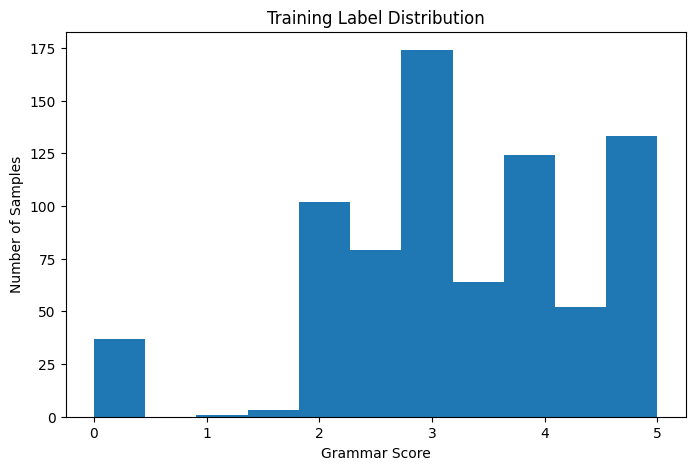

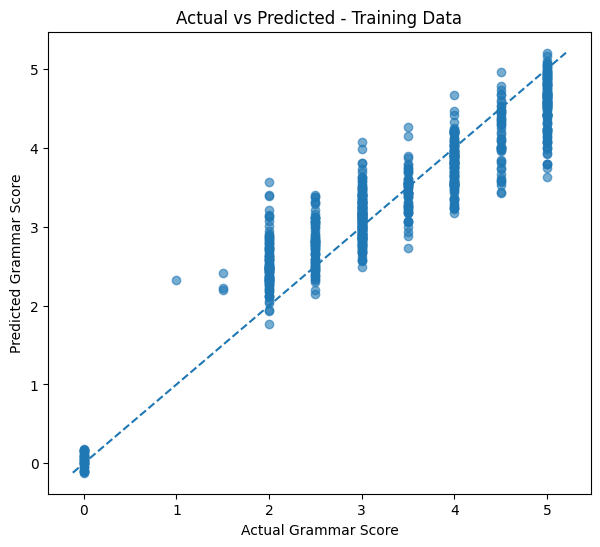

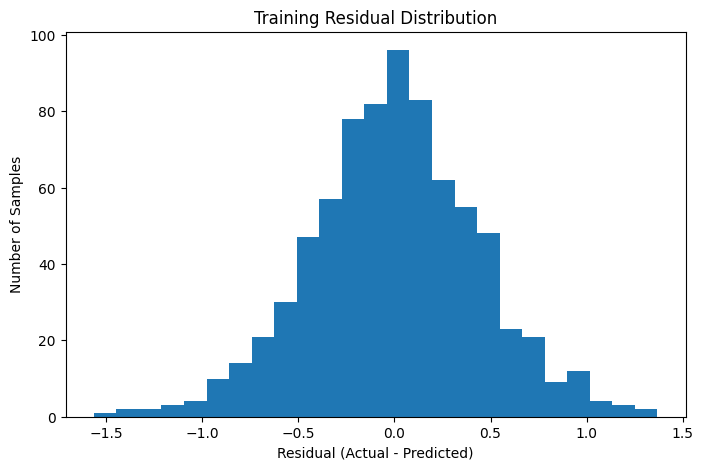

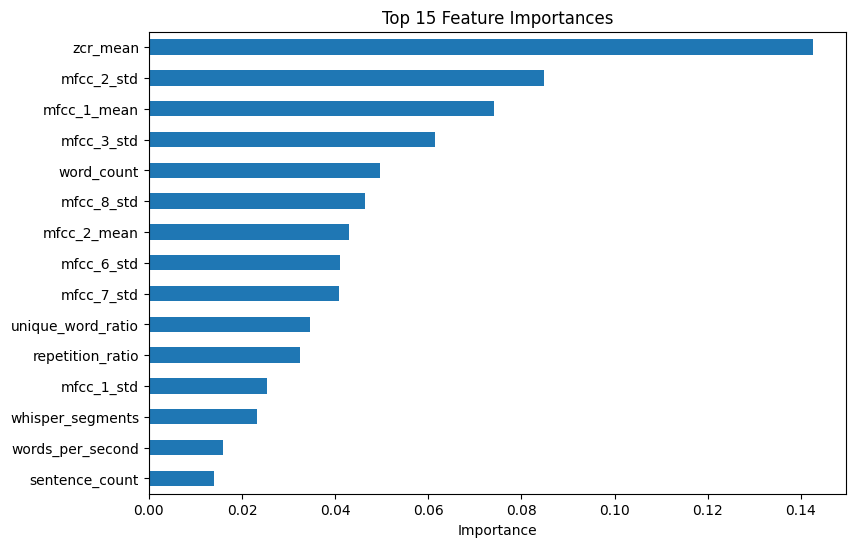

In [54]:
# Final Model Visualizations

import matplotlib.pyplot as plt
import numpy as np

# 1. Label distribution
plt.figure(figsize=(8, 5))
plt.hist(y_final, bins=11)
plt.xlabel("Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Training Label Distribution")
plt.show()


# 2. Actual vs predicted on training data
plt.figure(figsize=(7, 6))
plt.scatter(y_final, train_predictions, alpha=0.6)

min_val = min(y_final.min(), train_predictions.min())
max_val = max(y_final.max(), train_predictions.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual Grammar Score")
plt.ylabel("Predicted Grammar Score")
plt.title("Actual vs Predicted - Training Data")
plt.show()


# 3. Residual distribution
residuals = y_final - train_predictions

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=25)
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Number of Samples")
plt.title("Training Residual Distribution")
plt.show()


# 4. Feature importance
importance = pd.Series(
    final_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances")
plt.show()

# Final Approach and Results

## Objective
The goal was to predict grammar scores for spoken English audio samples using both acoustic and linguistic information extracted from the recordings.

## Data
- Training samples: 769
- Test samples: 216
- Audio duration: approximately 45–60 seconds
- Target: grammar score from 0 to 5

## Feature Engineering

Two types of features were extracted:

### 1. Linguistic Features
Transcripts were generated using OpenAI Whisper. From the transcripts, the following features were extracted:
- Word count
- Sentence count
- Average sentence length
- Unique word ratio
- Repetition ratio
- Filler word count
- Filler word ratio

### 2. Audio and Speech Features
Acoustic features were extracted directly from the audio:
- Duration
- RMS energy statistics
- Zero-crossing rate statistics
- MFCC mean and standard deviation features

Additional speech features were calculated from Whisper timestamps:
- Speech time
- Pause time
- Pause count
- Average pause
- Maximum pause
- Speech ratio
- Words per second
- Number of Whisper segments

This resulted in 46 features per audio sample.

## Model Selection

Several tree-based regression models were evaluated using 5-fold cross-validation:

| Model | RMSE | Pearson |
|---|---:|---:|
| Random Forest | 0.7596 | 0.7902 |
| LightGBM | 0.7517 | 0.7947 |
| XGBoost | 0.7431 | 0.8000 |
| Tuned XGBoost | **0.7424** | **0.8005** |

The tuned XGBoost model performed best and was selected for the final predictions.

## Final Model

The final XGBoost model used:
- 500 estimators
- Learning rate: 0.02
- Maximum depth: 3
- Minimum child weight: 3
- Subsample: 0.85
- Column subsample: 0.85
- L1 regularization: 0.05
- L2 regularization: 2.0

The model was retrained on all 769 training samples before generating predictions for the 216 test samples.

## Final Evaluation

Training RMSE: **0.4379**

5-Fold Cross-Validation RMSE: **0.7424**

5-Fold Cross-Validation Pearson Correlation: **0.8005**

The cross-validation results are the main indicator of expected generalization performance, while the training RMSE is reported separately as required.

## Submission

Predictions were generated for all 216 test samples and clipped to the valid score range of 0–5.

The final submission contains:
- 216 rows
- `filename`
- `label`
- No missing values